Olá, **Pedro**!

Meu nome é **Henrique Targino** e serei o revisor do seu projeto hoje.

Quando identificar um erro pela primeira vez, apenas vou apontá-lo para que você mesmo possa encontrá-lo e corrigi-lo. Ao longo do notebook também farei observações de melhoria e comentários sobre suas análises, pois meu objetivo é prepará-lo(a) para trabalhar como **Data Scientist** no mercado real.

Se não conseguir identificar o erro, na próxima iteração darei uma dica mais precisa com exemplos práticos. Estou aberto a feedbacks e discussões.

**Por favor, não mova, modifique ou exclua meus comentários.**

Você encontrará meus comentários em caixas coloridas:

<div class="alert alert-block alert-success">
<b>Comentário do revisor (Henrique Targino):</b> <a class="tocSkip"></a>
Sucesso. Tudo foi feito corretamente.
</div>

<div class="alert alert-block alert-warning">
<b>Comentário do revisor (Henrique Targino):</b> <a class="tocSkip"></a>
Atenção. Sugestão ou observação de melhoria.
</div>

<div class="alert alert-block alert-danger">
<b>Comentário do revisor (Henrique Targino):</b> <a class="tocSkip"></a>
Precisa de correção. O projeto não pode ser aceito com comentários em vermelho abertos.
</div>

Você pode me responder usando:

<div class="alert alert-block alert-info">
<b>Resposta do Aluno.</b> <a class="tocSkip"></a>
</div>

<div class="alert alert-block alert-success">
<b>Comentário geral do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Pedro, obrigado por enviar seu projeto! Ele está aprovado!

A análise exploratória cobre quase tudo o que o projeto pede: você conferiu o tamanho do conjunto, olhou a distribuição das idades com o `describe()` e com um histograma bem feito e mostrou 15 fotos com as idades, usando o gerador em vez de carregar todas as imagens na memória. As funções do modelo também estão bem estruturadas.

Deixei uma sugestão sobre o resultado do treino, pensando na próxima etapa.

Cada ponto está detalhado ao longo do notebook. Conte comigo para qualquer dúvida. Até breve!
</div>

## Inicialização

## Carregue os dados

O conjunto de dados é armazenado na pasta `/datasets/faces/`, onde você pode encontrar:
- A pasta `final_files` com 7,6k fotos
- O arquivo `labels.csv` com rótulos, com duas colunas: `file_name` e `real_age`

Dado que o número de arquivos de imagem é bastante alto, é aconselhável evitar a leitura de todos de uma vez, o que consumiria muito recursos computacionais. Recomendamos que você crie um gerador com o ImageDataGenerator. Este método foi explicado no Capítulo 3, Lição 7 deste curso.

O arquivo de rótulo pode ser carregado como um arquivo CSV normal.

Você pode fazer a EDA aqui, no Jupyter da plataforma, ou, se preferir, no Google Colab: nesse caso, baixe o `faces.zip` [desta pasta do Drive](https://drive.google.com/drive/folders/1ik4AkZcb-cG_Ga-Hu5rN1GianXFmkLZ8) e salve-o no seu Google Drive. A célula abaixo encontra os dados nos dois ambientes. No Colab, ela procura o arquivo na pasta raiz do "Meu Drive"; se você o salvou em outra pasta, mude a variável `CAMINHO_ZIP_DRIVE`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications.resnet import preprocess_input

## EDA

In [2]:

path = '/datasets/faces/'
labels = pd.read_csv(path + 'labels.csv')

train_datagen = ImageDataGenerator(rescale=1./255)

train_gen_flow = train_datagen.flow_from_dataframe(
        dataframe=labels,
        directory=path + 'final_files/',
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        seed=12345)


Found 7591 validated image filenames.


<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Boa, você leu os rótulos e criou o gerador com `flow_from_dataframe`, como o projeto recomenda, sem carregar as 7.591 fotos de uma vez na memória.
</div>

In [3]:
display(labels.head())

,file_name,real_age
0,000000.jpg,4
1,000001.jpg,18
2,000002.jpg,80
3,000003.jpg,50
4,000004.jpg,17


#### Verificando o tamanho do conjunto de dados

In [4]:
print('Quantidade de imagens', labels.shape[0])
print('Quantidade de colunas ', labels.shape[1])

Quantidade de imagens 7591
Quantidade de colunas  2


#### Carregando as informações gerais

In [5]:
labels.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7591 entries, 0 to 7590
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   file_name  7591 non-null   object
 1   real_age   7591 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 118.7+ KB


In [6]:
display(labels['real_age'].describe())

count    7591.000000
mean       31.201159
std        17.145060
min         1.000000
25%        20.000000
50%        29.000000
75%        41.000000
max       100.000000
Name: real_age, dtype: float64

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Correto: 7.591 fotos, sem ausentes, com idades de 1 a 100 anos (média de 31,2 e mediana de 29). Olhar o tamanho e o `describe()` antes de tudo dá a noção da escala do problema.
</div>

### Conclusões

O conjunto de dados possui 7.591 registros, sem valores ausentes nas colunas analisadas. As idades variam de 1 a 100 anos, com média de 31 anos e mediana de 29 anos. A distribuição apresenta uma diversidade considerável de faixas etárias, sendo adequada para iniciar o desenvolvimento de um modelo de estimativa de idade.

#### Histograma sobre a distribuição das idades

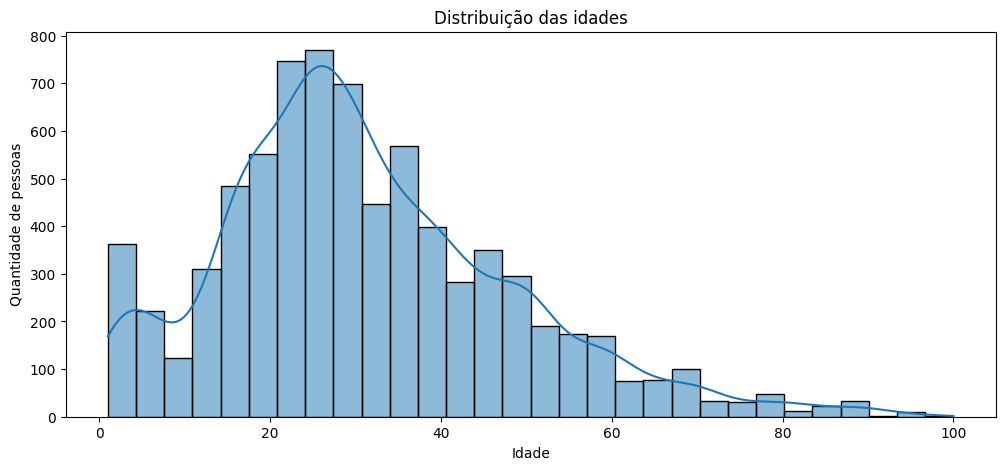

In [7]:
plt.figure(figsize=(12,5))

sns.histplot(labels['real_age'], bins=30, kde=True)

plt.title('Distribuição das idades')
plt.xlabel('Idade')
plt.ylabel('Quantidade de pessoas')

plt.show()

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Bom histograma, com título, eixos nomeados e a curva de densidade, que ajuda a ver a forma da distribuição.
</div>

#### imprimindo as primeiras 15 fotos

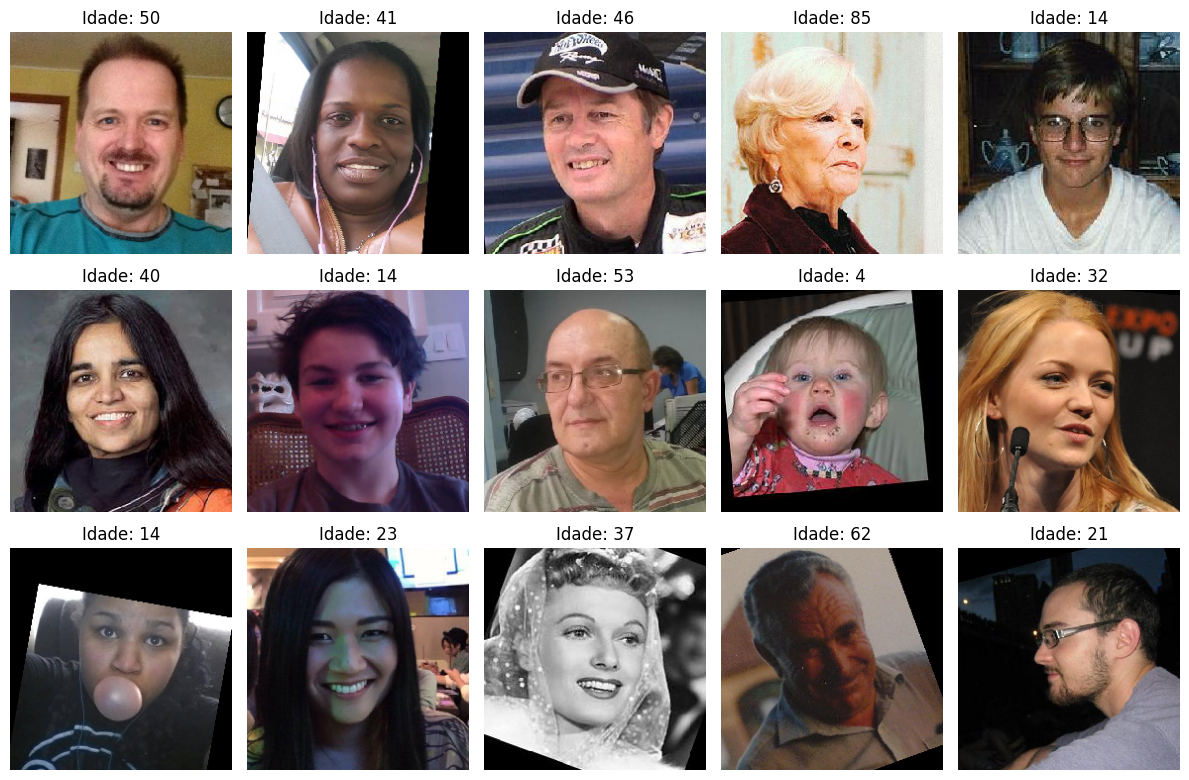

In [8]:
features, target = next(train_gen_flow)

fig = plt.figure(figsize=(12, 8))

for i in range(15):
    fig.add_subplot(3, 5, i + 1)

    plt.imshow(features[i])
    plt.title(f'Idade: {target[i]}')
    plt.axis('off')

plt.tight_layout()
plt.show()

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Ótimo: 15 fotos tiradas do gerador, com a idade real no título e idades bem variadas, de 4 a 85 anos. Ver as imagens ajuda a entender com o que o modelo vai trabalhar.
</div>

## Modelagem

Defina as funções necessárias para treinar o seu modelo.

As definições abaixo também serão verificadas pelos revisores do projeto, para que possam entender como você construiu o modelo.

In [9]:
def load_data(path, subset='training'):

    labels = pd.read_csv(path + 'labels.csv')

    datagen = ImageDataGenerator(
        validation_split=0.25,
        preprocessing_function=preprocess_input
    )

    gen_flow = datagen.flow_from_dataframe(
        dataframe=labels,
        directory=path + 'final_files/',
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        subset=subset,
        seed=12345
    )

    return gen_flow

In [10]:
def create_model(input_shape):

    backbone = ResNet50(input_shape=input_shape, weights='imagenet', include_top=False)

    #Congelando a rede
    backbone.trainable = False

    model = Sequential([backbone, GlobalAveragePooling2D(), Dense(1, activation='relu')])

    optimizer = Adam(learning_rate=0.0001)

    model.compile(
        optimizer=optimizer,
        loss='mean_squared_error',
        metrics=['mae']
    )

    return model


In [11]:
def train_model(model, train_data, test_data, batch_size=None, epochs=5):

    model.fit(
        train_data,
        validation_data=test_data,
        epochs=epochs,
        steps_per_epoch=len(train_data),
        validation_steps=len(test_data),
        verbose=2
    )

    return model

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

As funções do modelo estão bem montadas: a ResNet50 com os pesos do ImageNet, o `GlobalAveragePooling2D` e uma camada `Dense(1, activation='relu')` para prever a idade, com o erro quadrático médio como perda, o MAE como métrica e 25% das fotos separadas para validação.
</div>

### Resultado

Execute o treinamento na célula abaixo e mantenha a saída visível.

In [58]:
path =  '/content/drive/MyDrive/faces/'

train_data = load_data(path, subset='training')
test_data = load_data(path, subset='validation')

model = create_model((224, 224, 3))

model = train_model(model, train_data, test_data)

Found 5694 validated image filenames.
Found 1897 validated image filenames.
Epoch 1/5
178/178 - 650s - 4s/step - loss: 889.8293 - mae: 24.7799 - val_loss: 534.5197 - val_mae: 18.1928
Epoch 2/5
178/178 - 50s - 283ms/step - loss: 478.0353 - mae: 16.6955 - val_loss: 357.3333 - val_mae: 14.3371
Epoch 3/5
178/178 - 41s - 230ms/step - loss: 363.9821 - mae: 14.4067 - val_loss: 320.7112 - val_mae: 13.7746
Epoch 4/5
178/178 - 41s - 231ms/step - loss: 335.4256 - mae: 13.9877 - val_loss: 308.6234 - val_mae: 13.6590
Epoch 5/5
178/178 - 42s - 235ms/step - loss: 321.8380 - mae: 13.7939 - val_loss: 297.6031 - val_mae: 13.4827


#### Conclusão

O modelo foi treinado utilizando a arquitetura ResNet50 com pesos pré-treinados no ImageNet, mantendo a rede convolucional congelada e adicionando as camadas GlobalAveragePooling2D e Dense para realizar a previsão da idade.

Ao longo das cinco épocas, foi possível observar uma redução progressiva dos erros de treinamento e validação. Ao final, o modelo alcançou um MAE de aproximadamente 13,48 anos no conjunto de validação, indicando que as previsões apresentam um erro absoluto médio de cerca de 13,48 anos em relação às idades reais.

Os resultados demonstram que o modelo conseguiu aprender padrões relevantes nas imagens e melhorar seu desempenho durante o treinamento, sem apresentar sinais evidentes de overfitting nas cinco épocas realizadas.

<div class="alert alert-block alert-warning">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Pensando na próxima etapa do projeto: o MAE de validação de 13,48 anos ainda fica acima de 8, que é o valor esperado para o modelo. Com a ResNet50 inteira congelada (`backbone.trainable = False`) e só 5 épocas, a rede aprende pouco sobre os rostos, então vale testar essas duas escolhas.

Vale também ligar o resultado ao uso real: na verificação de quem compra bebida alcoólica, um erro médio de 13 anos não consegue separar um adolescente de um adulto, e a conclusão pode discutir isso.
</div>

##### Conclusão geral do projeto

O projeto teve como objetivo desenvolver um modelo de Deep Learning capaz de estimar a idade de pessoas a partir de fotografias, utilizando técnicas de visão computacional.

Durante o desenvolvimento, foi realizada a análise dos dados, o carregamento e pré-processamento das imagens, a separação dos conjuntos de treinamento e validação e a construção de um modelo baseado na arquitetura ResNet50, utilizando Transfer Learning.

A utilização de uma rede pré-treinada permitiu aproveitar características visuais previamente aprendidas, adaptando o modelo para uma tarefa de regressão, na qual a saída corresponde à idade estimada da pessoa.

Ao final do treinamento, o modelo alcançou um MAE de 13,48 anos no conjunto de validação. Embora tenha apresentado uma evolução consistente, esse resultado indica que ainda existe margem para melhorar a precisão das estimativas.

O desenvolvimento deste projeto permitiu aplicar conceitos de Redes Neurais Convolucionais, Transfer Learning, pré-processamento de imagens e avaliação de modelos de Deep Learning, demonstrando como essas técnicas podem ser utilizadas em problemas reais de visão computacional.